<a href="https://colab.research.google.com/github/galhkoernia/Footer-Profesional-02/blob/main/LKM_ConditionMonitoringofHydraulicSystems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)

import kagglehub

path = kagglehub.dataset_download(
    "jjacostupa/condition-monitoring-of-hydraulic-systems"
)

print("Dataset:", path)

100%|██████████| 91.1M/91.1M [00:00<00:00, 152MB/s]

Extracting files...


Dataset: /root/.cache/kagglehub/datasets/jjacostupa/condition-monitoring-of-hydraulic-systems/versions/1


In [2]:
# Baca file
files = glob.glob(path + "/**/*.txt", recursive=True)

for f in files:
    print(os.path.basename(f))

VS1.txt
FS1.txt
PS5.txt
CE.txt
PS1.txt
profile.txt
TS4.txt
CP.txt
EPS1.txt
FS2.txt
PS6.txt
SE.txt
TS2.txt
PS4.txt
description.txt
TS3.txt
documentation.txt
PS3.txt
PS2.txt
TS1.txt


In [3]:
sensor_names = [
    "PS1", "PS2", "PS3", "PS4", "PS5", "PS6",
    "EPS1",
    "FS1", "FS2",
    "TS1", "TS2", "TS3", "TS4",
    "VS1"
]

sensor_data = {}

for sensor in sensor_names:
    file = [f for f in files if os.path.basename(f) == sensor + ".txt"][0]
    sensor_data[sensor] = pd.read_csv(
        file,
        sep="\t",
        header=None
    )

profile_file = [
    f for f in files if os.path.basename(f) == "profile.txt"
][0]

profile = pd.read_csv(
    profile_file,
    sep="\t",
    header=None
)

print("Jumlah siklus:", len(profile))
print("Jumlah sensor:", len(sensor_data))

for sensor in sensor_names:
    print(sensor, sensor_data[sensor].shape)

Jumlah siklus: 2205
Jumlah sensor: 14
PS1 (2205, 6000)
PS2 (2205, 6000)
PS3 (2205, 6000)
PS4 (2205, 6000)
PS5 (2205, 6000)
PS6 (2205, 6000)
EPS1 (2205, 6000)
FS1 (2205, 600)
FS2 (2205, 600)
TS1 (2205, 60)
TS2 (2205, 60)
TS3 (2205, 60)
TS4 (2205, 60)
VS1 (2205, 60)


In [4]:
profile.columns = [
    "cooler",
    "valve",
    "pump",
    "accumulator",
    "stable"
]

print(profile["pump"].value_counts().sort_index())
print()

print("Stable flag:")
print(profile["stable"].value_counts().sort_index())

pump
0    1221
1     492
2     492
Name: count, dtype: int64

Stable flag:
stable
0    1449
1     756
Name: count, dtype: int64


In [5]:
stable_idx = profile["stable"] == 0

profile_stable = profile[stable_idx].reset_index(drop=True)

print("Siklus stabil:", len(profile_stable))
print(profile_stable["pump"].value_counts().sort_index())

Siklus stabil: 1449
pump
0    489
1    480
2    480
Name: count, dtype: int64


In [6]:
# Ekstraksi 56 fitur
features = {}

for sensor in sensor_names:
    data = sensor_data[sensor].values[stable_idx]

    features[sensor + "_mean"] = data.mean(axis=1)
    features[sensor + "_std"] = data.std(axis=1)
    features[sensor + "_min"] = data.min(axis=1)
    features[sensor + "_max"] = data.max(axis=1)

X = pd.DataFrame(features)
y = profile_stable["pump"]

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Ukuran X: (1449, 56)
Ukuran y: (1449,)


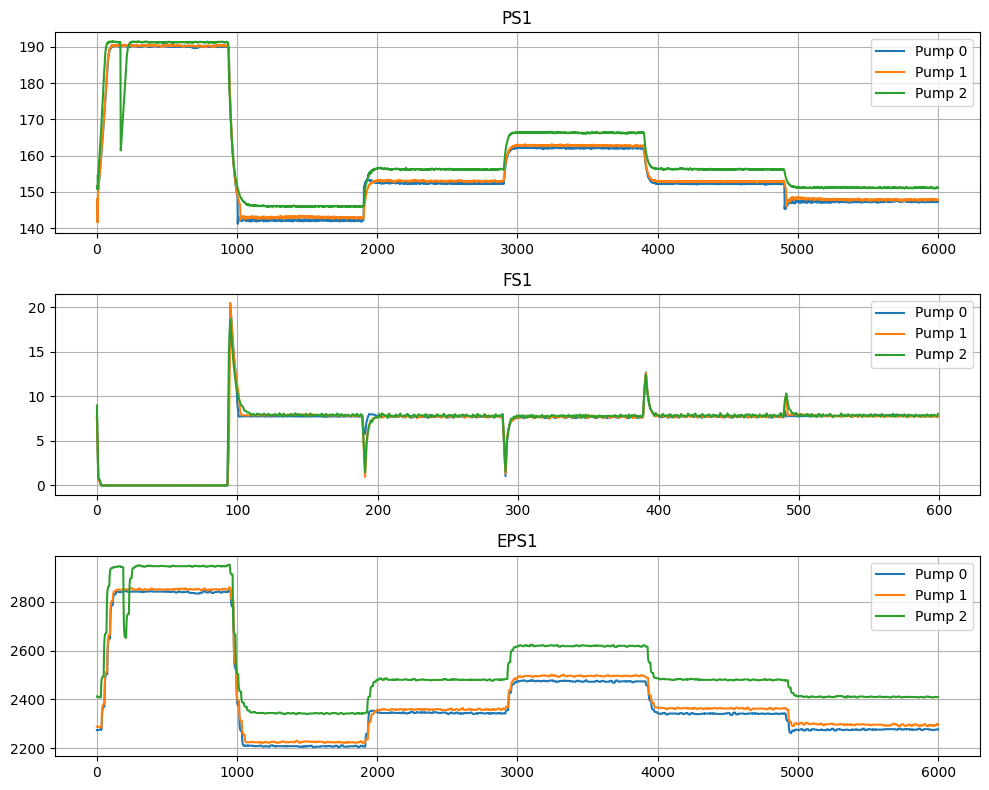

In [7]:
# Plot
fig, ax = plt.subplots(3, 1, figsize=(10, 8))

for label in [0, 1, 2]:
    idx = np.where(y.values == label)[0][0]

    ax[0].plot(sensor_data["PS1"].iloc[idx].values,
               label=f"Pump {label}")

    ax[1].plot(sensor_data["FS1"].iloc[idx].values,
               label=f"Pump {label}")

    ax[2].plot(sensor_data["EPS1"].iloc[idx].values,
               label=f"Pump {label}")

ax[0].set_title("PS1")
ax[1].set_title("FS1")
ax[2].set_title("EPS1")

for a in ax:
    a.legend()
    a.grid()

plt.tight_layout()
plt.show()

In [8]:
# Membuat kelompok eksperimen
condition_cols = ["cooler", "valve", "pump", "accumulator"]

conditions = profile_stable[condition_cols].astype(str).agg("_".join, axis=1)

groups = (conditions != conditions.shift()).cumsum()

print("Jumlah kelompok eksperimen:", groups.nunique())
print()
print("Ukuran setiap kelompok:")
print(groups.value_counts().sort_index())

Jumlah kelompok eksperimen: 144

Ukuran setiap kelompok:
1      10
2      10
3      10
4      10
5      10
       ..
140    10
141    10
142    10
143    10
144    19
Name: count, Length: 144, dtype: int64


In [9]:
# Menambahkan group ke dataset
data = X.copy()
data["target"] = y.values
data["group"] = groups.values

print(data.head())
print()
print("Distribusi kelas:")
print(data["target"].value_counts().sort_index())

     PS1_mean    PS1_std  PS1_min  PS1_max    PS2_mean    PS2_std  PS2_min  \
0  174.891227  19.799559   140.23   190.06  124.498240  57.637735      0.0   
1  156.366353  16.208856   133.27   189.98  104.530172  46.206975      0.0   
2  156.485143  15.378330   137.14   189.98  105.118359  46.101129      0.0   
3  167.473575  20.910023   138.86   189.95  116.701433  54.351335      0.0   
4  167.305588  20.901329   139.42   189.93  116.617816  54.331431      0.0   

   PS2_max  PS3_mean   PS3_std  ...   TS4_mean   TS4_std  TS4_min  TS4_max  \
0   165.85  1.043820  0.850933  ...  49.562633  0.087550   49.355   49.684   
1   165.38  1.717962  1.049236  ...  49.587650  0.078059   49.406   49.680   
2   163.79  1.641115  0.896385  ...  49.641000  0.068046   49.469   49.738   
3   165.82  1.311191  0.990271  ...  49.497000  0.053713   49.402   49.621   
4   165.90  1.304355  0.997192  ...  49.511100  0.047689   49.422   49.605   

   VS1_mean   VS1_std  VS1_min  VS1_max  target  group  
0  0.

In [10]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

print("TRAIN")
print("Siklus :", len(X_train))
print("Group  :", groups_train.nunique())
print(y_train.value_counts().sort_index())

print("\nTEST")
print("Siklus :", len(X_test))
print("Group  :", groups_test.nunique())
print(y_test.value_counts().sort_index())

TRAIN
Siklus : 1159
Group  : 115
pump
0    399
1    370
2    390
Name: count, dtype: int64

TEST
Siklus : 290
Group  : 29
pump
0     90
1    110
2     90
Name: count, dtype: int64


In [11]:
print(
    "Group overlap:",
    set(groups_train.unique()) & set(groups_test.unique())
)

Group overlap: set()


In [12]:
# SVM Baseline
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
import time

# SVM + preprocessing
model = Pipeline([
    ("constant", VarianceThreshold(threshold=0)),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

# Grid SVM
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": ["scale", 0.01, 0.1, 1]
}

# CV berdasarkan kelompok eksperimen
cv = GroupKFold(n_splits=5)

grid = GridSearchCV(
    model,
    param_grid,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
    return_train_score=False
)

# Training
start = time.time()

grid.fit(
    X_train,
    y_train,
    groups=groups_train
)

train_time = time.time() - start

print("Fitur awal              :", X_train.shape[1])

constant_mask = grid.best_estimator_.named_steps["constant"].get_support()
print("Fitur konstan           :", (~constant_mask).sum())
print("Fitur input SVM         :", constant_mask.sum())

print("Parameter terbaik       :", grid.best_params_)
print("CV Macro-F1             :", round(grid.best_score_, 4))
print("Waktu latih (s)         :", round(train_time, 2))

Fitur awal              : 56
Fitur konstan           : 2
Fitur input SVM         : 54
Parameter terbaik       : {'svm__C': 100, 'svm__gamma': 0.01}
CV Macro-F1             : 0.9837
Waktu latih (s)         : 11.96


In [13]:
results = pd.DataFrame(grid.cv_results_)

best = results.loc[grid.best_index_]

mean_f1 = best["mean_test_score"]
std_f1 = best["std_test_score"]

print(
    f"CV Macro-F1 = {mean_f1:.4f} ± {std_f1:.4f}"
)

CV Macro-F1 = 0.9837 ± 0.0089


In [14]:
# PCA untuk melihat cumulative explained variance

from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

pca_check = Pipeline([
    ("constant", VarianceThreshold(threshold=0)),
    ("scaler", StandardScaler()),
    ("pca", PCA())
])

pca_check.fit(X_train, y_train)

pca = pca_check.named_steps["pca"]

cum_evr = np.cumsum(pca.explained_variance_ratio_)

for threshold in [0.80, 0.90, 0.95, 0.99]:
    q = np.argmax(cum_evr >= threshold) + 1
    print(f"EVR >= {threshold:.0%} : {q} komponen")

EVR >= 80% : 3 komponen
EVR >= 90% : 6 komponen
EVR >= 95% : 9 komponen
EVR >= 99% : 15 komponen


In [15]:
q_candidates = [2, 4, 6, 8, 10, 15, 20]

pca_results = []

for q in q_candidates:

    model_pca = Pipeline([
        ("constant", VarianceThreshold(threshold=0)),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=q)),
        ("svm", SVC(kernel="rbf"))
    ])

    grid_pca = GridSearchCV(
        model_pca,
        param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    grid_pca.fit(
        X_train,
        y_train,
        groups=groups_train
    )

    result = grid_pca.cv_results_
    best_idx = grid_pca.best_index_

    pca_results.append({
        "q": q,
        "q_efektif": q,
        "CV_macro_F1": result["mean_test_score"][best_idx],
        "SD": result["std_test_score"][best_idx],
        "C": grid_pca.best_params_["svm__C"],
        "gamma": grid_pca.best_params_["svm__gamma"]
    })

pca_results = pd.DataFrame(pca_results)

print(pca_results.round(4))

    q  q_efektif  CV_macro_F1      SD    C  gamma
0   2          2       0.4666  0.0409  100      1
1   4          4       0.6636  0.0553   10  scale
2   6          6       0.6973  0.0386   10    0.1
3   8          8       0.6969  0.0712  100  scale
4  10         10       0.8239  0.0601  100  scale
5  15         15       0.9501  0.0152  100   0.01
6  20         20       0.9793  0.0102  100   0.01


In [16]:
# Kelompok fitur berdasarkan kanal sensor

pressure = ["PS1", "PS2", "PS3", "PS4", "PS5", "PS6"]
power = ["EPS1"]
flow = ["FS1", "FS2"]
temperature = ["TS1", "TS2", "TS3", "TS4"]
vibration = ["VS1"]

def get_features(sensors):
    return [
        f"{sensor}_{stat}"
        for sensor in sensors
        for stat in ["mean", "std", "min", "max"]
    ]

all_sensors = pressure + power + flow + temperature + vibration

feature_groups = {
    "Acuan": all_sensors,
    "Tanpa temperatur": pressure + power + flow + vibration,
    "Tanpa debit": pressure + power + temperature + vibration,
    "Tanpa tekanan": power + flow + temperature + vibration
}

for name, sensors in feature_groups.items():
    print(name, ":", len(sensors), "kanal,", len(get_features(sensors)), "fitur")

Acuan : 14 kanal, 56 fitur
Tanpa temperatur : 10 kanal, 40 fitur
Tanpa debit : 12 kanal, 48 fitur
Tanpa tekanan : 8 kanal, 32 fitur


In [18]:
def run_svm(Xtr, ytr, groups_tr):

    model = Pipeline([
        ("constant", VarianceThreshold(threshold=0)),
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf"))
    ])

    grid = GridSearchCV(
        model,
        param_grid,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    start = time.time()

    grid.fit(
        Xtr,
        ytr,
        groups=groups_tr
    )

    elapsed = time.time() - start

    best = grid.cv_results_
    idx = grid.best_index_

    return {
        "model": grid.best_estimator_,
        "best_params": grid.best_params_,
        "mean_f1": best["mean_test_score"][idx],
        "std_f1": best["std_test_score"][idx],
        "time": elapsed
    }

In [19]:
ablation_results = []

for name, sensors in feature_groups.items():

    columns = get_features(sensors)

    print(f"\nMenjalankan: {name}")
    print(f"Fitur: {len(columns)}")

    result = run_svm(
        X_train[columns],
        y_train,
        groups_train
    )

    print("Best parameter :", result["best_params"])
    print("CV Macro-F1    :", round(result["mean_f1"], 4))
    print("SD             :", round(result["std_f1"], 4))
    print("Waktu          :", round(result["time"], 2), "detik")

    ablation_results.append({
        "Konfigurasi": name,
        "Kanal": len(sensors),
        "Fitur awal": len(columns),
        "CV Macro-F1": result["mean_f1"],
        "SD": result["std_f1"],
        "C": result["best_params"]["svm__C"],
        "gamma": result["best_params"]["svm__gamma"],
        "Waktu (s)": result["time"]
    })

ablation_results = pd.DataFrame(ablation_results)

baseline_f1 = ablation_results.loc[
    ablation_results["Konfigurasi"] == "Acuan",
    "CV Macro-F1"
].iloc[0]

ablation_results["Delta F1"] = (
    ablation_results["CV Macro-F1"] - baseline_f1
)

print("\n=== HASIL ABLASI ===")
print(ablation_results.round(4))


Menjalankan: Acuan
Fitur: 56
Best parameter : {'svm__C': 100, 'svm__gamma': 0.01}
CV Macro-F1    : 0.9837
SD             : 0.0089
Waktu          : 4.55 detik

Menjalankan: Tanpa temperatur
Fitur: 40
Best parameter : {'svm__C': 100, 'svm__gamma': 0.01}
CV Macro-F1    : 0.992
SD             : 0.005
Waktu          : 4.05 detik

Menjalankan: Tanpa debit
Fitur: 48
Best parameter : {'svm__C': 100, 'svm__gamma': 0.01}
CV Macro-F1    : 0.984
SD             : 0.0099
Waktu          : 6.53 detik

Menjalankan: Tanpa tekanan
Fitur: 32
Best parameter : {'svm__C': 100, 'svm__gamma': 0.01}
CV Macro-F1    : 0.9883
SD             : 0.0066
Waktu          : 4.0 detik

=== HASIL ABLASI ===
        Konfigurasi  Kanal  Fitur awal  CV Macro-F1      SD    C  gamma  \
0             Acuan     14          56       0.9837  0.0089  100   0.01   
1  Tanpa temperatur     10          40       0.9920  0.0050  100   0.01   
2       Tanpa debit     12          48       0.9840  0.0099  100   0.01   
3     Tanpa tekanan  

In [20]:
# Model final untuk testing

final_models = {}

# 1. Acuan
final_models["Acuan"] = (
    X_train,
    X_test
)

# 2. PCA q terpilih
final_models["PCA q=20"] = (
    X_train,
    X_test
)

# 3-5. Ablasi
for name, sensors in feature_groups.items():
    if name != "Acuan":
        cols = get_features(sensors)

        final_models[name] = (
            X_train[cols],
            X_test[cols]
        )

print(final_models.keys())

dict_keys(['Acuan', 'PCA q=20', 'Tanpa temperatur', 'Tanpa debit', 'Tanpa tekanan'])


In [21]:
from sklearn.metrics import f1_score, recall_score
import time

test_results = []

# Kolom PCA tidak perlu dipotong manual.
# Pipeline akan melakukan preprocessing dari training.

configs = {
    "Acuan": None,
    "PCA q=20": "pca",
    "Tanpa temperatur": feature_groups["Tanpa temperatur"],
    "Tanpa debit": feature_groups["Tanpa debit"],
    "Tanpa tekanan": feature_groups["Tanpa tekanan"]
}

for name, config in configs.items():

    if config == "pca":

        Xtr = X_train
        Xte = X_test

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=20)),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    elif config is None:

        Xtr = X_train
        Xte = X_test

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    else:

        columns = get_features(config)

        Xtr = X_train[columns]
        Xte = X_test[columns]

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    start = time.time()

    model.fit(Xtr, y_train)
    y_pred = model.predict(Xte)

    elapsed = (time.time() - start) * 1000

    macro_f1 = f1_score(
        y_test,
        y_pred,
        average="macro"
    )

    recall_heavy = recall_score(
        y_test,
        y_pred,
        labels=[2],
        average=None
    )[0]

    test_results.append({
        "Konfigurasi": name,
        "Dimensi input SVM": Xtr.shape[1],
        "CV Macro-F1": (
            0.9837 if name == "Acuan" else
            0.9793 if name == "PCA q=20" else
            ablation_results.loc[
                ablation_results["Konfigurasi"] == name,
                "CV Macro-F1"
            ].iloc[0]
        ),
        "Test Macro-F1": macro_f1,
        "Recall berat": recall_heavy,
        "Waktu prediksi (ms)": elapsed
    })

test_results = pd.DataFrame(test_results)

print(test_results.round(4))

        Konfigurasi  Dimensi input SVM  CV Macro-F1  Test Macro-F1  \
0             Acuan                 56       0.9837         0.9933   
1          PCA q=20                 56       0.9793         0.9865   
2  Tanpa temperatur                 40       0.9920         0.9899   
3       Tanpa debit                 48       0.9840         0.9899   
4     Tanpa tekanan                 32       0.9883         0.9665   

   Recall berat  Waktu prediksi (ms)  
0        0.9778             106.8673  
1        0.9778              63.3819  
2        0.9778              56.7331  
3        0.9778              57.3246  
4        0.9778             126.9035  


In [22]:
print("=== Classification Report Acuan ===")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Tidak bocor",
            "Ringan",
            "Berat"
        ]
    )
)

=== Classification Report Acuan ===
              precision    recall  f1-score   support

 Tidak bocor       1.00      1.00      1.00        90
      Ringan       0.98      0.93      0.95       110
       Berat       0.92      0.98      0.95        90

    accuracy                           0.97       290
   macro avg       0.97      0.97      0.97       290
weighted avg       0.97      0.97      0.97       290



In [23]:
# EvalFinal
predictions = {}
final_models = {}

configs = {
    "Acuan": None,
    "PCA q=20": "pca",
    "Tanpa temperatur": feature_groups["Tanpa temperatur"],
    "Tanpa debit": feature_groups["Tanpa debit"],
    "Tanpa tekanan": feature_groups["Tanpa tekanan"]
}

for name, config in configs.items():

    if config == "pca":

        Xtr = X_train
        Xte = X_test

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=20)),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    elif config is None:

        Xtr = X_train
        Xte = X_test

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    else:

        columns = get_features(config)

        Xtr = X_train[columns]
        Xte = X_test[columns]

        model = Pipeline([
            ("constant", VarianceThreshold(threshold=0)),
            ("scaler", StandardScaler()),
            ("svm", SVC(
                kernel="rbf",
                C=100,
                gamma=0.01
            ))
        ])

    model.fit(Xtr, y_train)

    pred = model.predict(Xte)

    predictions[name] = pred
    final_models[name] = model


In [24]:
final_results = []

for name, pred in predictions.items():

    if name == "Acuan":
        dim = 54
    elif name == "PCA q=20":
        dim = 20
    elif name == "Tanpa temperatur":
        dim = 40
    elif name == "Tanpa debit":
        dim = 48
    else:
        dim = 32

    final_results.append({
        "Konfigurasi": name,
        "Dimensi input SVM": dim,
        "Test Accuracy": accuracy_score(y_test, pred),
        "Test Macro-F1": f1_score(
            y_test, pred, average="macro"
        ),
        "Recall berat": recall_score(
            y_test, pred,
            labels=[2],
            average=None
        )[0]
    })

final_results = pd.DataFrame(final_results)

print(final_results.round(4))

        Konfigurasi  Dimensi input SVM  Test Accuracy  Test Macro-F1  \
0             Acuan                 54         0.9931         0.9933   
1          PCA q=20                 20         0.9862         0.9865   
2  Tanpa temperatur                 40         0.9897         0.9899   
3       Tanpa debit                 48         0.9897         0.9899   
4     Tanpa tekanan                 32         0.9655         0.9665   

   Recall berat  
0        0.9778  
1        0.9778  
2        0.9778  
3        0.9778  
4        0.9778  


In [25]:
# Classification Report
for name, pred in predictions.items():

    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            pred,
            target_names=[
                "Tidak bocor",
                "Ringan",
                "Berat"
            ]
        )
    )


Acuan
              precision    recall  f1-score   support

 Tidak bocor       1.00      1.00      1.00        90
      Ringan       0.98      1.00      0.99       110
       Berat       1.00      0.98      0.99        90

    accuracy                           0.99       290
   macro avg       0.99      0.99      0.99       290
weighted avg       0.99      0.99      0.99       290


PCA q=20
              precision    recall  f1-score   support

 Tidak bocor       1.00      1.00      1.00        90
      Ringan       0.98      0.98      0.98       110
       Berat       0.98      0.98      0.98        90

    accuracy                           0.99       290
   macro avg       0.99      0.99      0.99       290
weighted avg       0.99      0.99      0.99       290


Tanpa temperatur
              precision    recall  f1-score   support

 Tidak bocor       1.00      1.00      1.00        90
      Ringan       0.98      0.99      0.99       110
       Berat       0.99      0.98      0

In [26]:
# Confusion matrix
for name, pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1, 2]
    )

    print("\n", name)
    print(cm)


 Acuan
[[ 90   0   0]
 [  0 110   0]
 [  0   2  88]]

 PCA q=20
[[ 90   0   0]
 [  0 108   2]
 [  0   2  88]]

 Tanpa temperatur
[[ 90   0   0]
 [  0 109   1]
 [  0   2  88]]

 Tanpa debit
[[ 90   0   0]
 [  0 109   1]
 [  0   2  88]]

 Tanpa tekanan
[[ 90   0   0]
 [  0 102   8]
 [  0   2  88]]


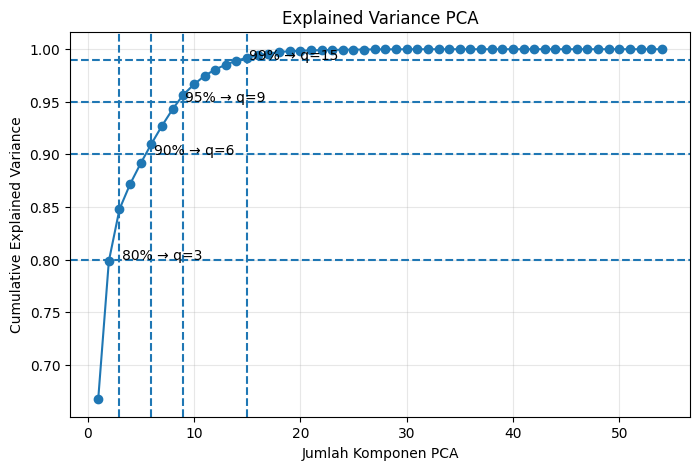

In [27]:
# Visualisasi cumulative explained variance PCA
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cum_evr) + 1),
    cum_evr,
    marker="o"
)

thresholds = [0.80, 0.90, 0.95, 0.99]

for threshold in thresholds:
    q = np.argmax(cum_evr >= threshold) + 1

    plt.axhline(
        threshold,
        linestyle="--"
    )

    plt.axvline(
        q,
        linestyle="--"
    )

    plt.text(
        q + 0.2,
        threshold,
        f"{threshold:.0%} → q={q}"
    )

plt.xlabel("Jumlah Komponen PCA")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance PCA")
plt.grid(alpha=0.3)

plt.show()

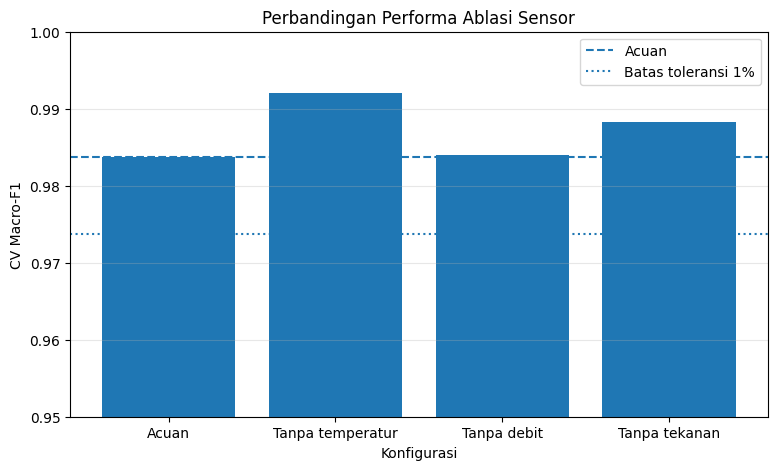

In [28]:
# perbandingan CV Macro
plt.figure(figsize=(9, 5))

plt.bar(
    ablation_results["Konfigurasi"],
    ablation_results["CV Macro-F1"]
)

plt.axhline(
    0.9837,
    linestyle="--",
    label="Acuan"
)

plt.axhline(
    0.9737,
    linestyle=":",
    label="Batas toleransi 1%"
)

plt.ylabel("CV Macro-F1")
plt.xlabel("Konfigurasi")
plt.title("Perbandingan Performa Ablasi Sensor")
plt.ylim(0.95, 1.00)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

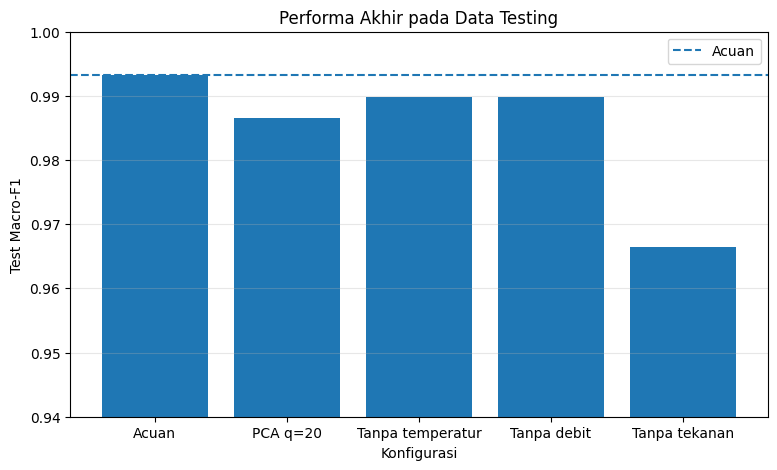

In [29]:
# Test Performa
plt.figure(figsize=(9, 5))

plt.bar(
    final_results["Konfigurasi"],
    final_results["Test Macro-F1"]
)

plt.axhline(
    final_results.loc[
        final_results["Konfigurasi"] == "Acuan",
        "Test Macro-F1"
    ].iloc[0],
    linestyle="--",
    label="Acuan"
)

plt.ylabel("Test Macro-F1")
plt.xlabel("Konfigurasi")
plt.title("Performa Akhir pada Data Testing")
plt.ylim(0.94, 1.00)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [32]:
# # Confusion Matrix
# from sklearn.metrics import ConfusionMatrixDisplay

# for name, pred in predictions.items():

#     fig, ax = plt.subplots(figsize=(5, 4))

#     ConfusionMatrixDisplay.from_predictions(
#         y_test,
#         pred,
#         labels=[0, 1, 2],
#         display_labels=[
#             "Tidak bocor",
#             "Ringan",
#             "Berat"
#         ],
#         cmap="Blues",
#         ax=ax
#     )

#     ax.set_title(f"Confusion Matrix - {name}")

#     plt.tight_layout()
#     plt.show()

In [31]:
# Hasil CV dan testin
comparison = final_results[
    ["Konfigurasi", "Test Macro-F1"]
].copy()

comparison["CV Macro-F1"] = [
    0.9837,
    0.9793,
    0.9920,
    0.9840,
    0.9883
]

comparison = comparison[
    ["Konfigurasi", "CV Macro-F1", "Test Macro-F1"]
]

print(comparison)

        Konfigurasi  CV Macro-F1  Test Macro-F1
0             Acuan       0.9837       0.993252
1          PCA q=20       0.9793       0.986532
2  Tanpa temperatur       0.9920       0.989889
3       Tanpa debit       0.9840       0.989889
4     Tanpa tekanan       0.9883       0.966503
